In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("C:/Users/Kenish/Desktop/powerbi/Indian-Startup-Funding-Analytics/data/startup_funding.csv")
df.shape

(3044, 10)

In [3]:
df.head()

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Sr No              3044 non-null   int64
 1   Date dd/mm/yyyy    3044 non-null   str  
 2   Startup Name       3044 non-null   str  
 3   Industry Vertical  2873 non-null   str  
 4   SubVertical        2108 non-null   str  
 5   City  Location     2864 non-null   str  
 6   Investors Name     3020 non-null   str  
 7   InvestmentnType    3040 non-null   str  
 8   Amount in USD      2084 non-null   str  
 9   Remarks            419 non-null    str  
dtypes: int64(1), str(9)
memory usage: 593.3 KB


In [5]:
df.columns

Index(['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical',
       'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType',
       'Amount in USD', 'Remarks'],
      dtype='str')

In [6]:
df = df.rename(columns={
    'sr.no': 'serial_no',
    'Date dd/mm/yyyy': 'funding_date',
    'Startup Name': 'startup_name',
    'Industry Vertical': 'industry',
    'SubVertical': 'sub_vertical',
    'City  Location': 'city',
    'Investors Name': 'investors',
    'InvestmentnType': 'investment_type',
    'Amount in USD': 'amount_usd',
    'Remarks': 'remarks'
})
df.head()

,Sr No,funding_date,startup_name,industry,sub_vertical,city,investors,investment_type,amount_usd,remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN


In [7]:
text_columns = [
    'startup_name',
    'industry',
    'sub_vertical',
    'city',
    'investors',
    'investment_type',
    'remarks'
]
for col in text_columns:
    df[col] = df[col].astype('string').str.strip()

In [8]:
df['city'] = df['city'].replace({
    'Bangalore':'Bengaluru',
    'Gurgaon':'Gurugram'
})

In [9]:
df['city'].value_counts().head(15)

city
Bengaluru     841
Mumbai        567
New Delhi     421
Gurugram      337
Pune          105
Hyderabad      99
Chennai        97
Noida          92
Ahmedabad      38
Delhi          34
Jaipur         30
Kolkata        21
Indore         13
Chandigarh     11
Goa            10
Name: count, dtype: int64[pyarrow]

In [10]:
df['industry'] = (
    df['industry']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

In [11]:
industry_mapping = {
    'eCommerce': 'E-Commerce',
    'Ecommerce': 'E-Commerce',
    'ecommerce': 'E-Commerce',
    'E-Commerce': 'E-Commerce',
    
    'Ed-Tech': 'EdTech',
    'Edtech': 'EdTech',
    
    'Fin-Tech': 'FinTech',
    'Fintech': 'FinTech'
}

df['industry'] = df['industry'].replace(industry_mapping)

In [12]:
df['investment_type'] = (
    df['investment_type']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

In [13]:
investment_mapping = {
    'Seed/ Angel Funding': 'Seed/Angel Funding',
    'Seed / Angel Funding': 'Seed/Angel Funding',
    'Seed/Angel Funding': 'Seed/Angel Funding',
    'Seed Angel Funding': 'Seed/Angel Funding',
    'Seed\nFunding': 'Seed Funding'
}
df['investment_type'] = df['investment_type'].replace(investment_mapping)
df['investment_type'].value_counts().head(20)

investment_type
Private Equity          1356
Seed Funding            1355
Seed/Angel Funding       130
Seed\\nFunding            30
Debt Funding              25
Series A                  24
Series B                  20
Series C                  14
Series D                  12
Angel / Seed Funding       8
Seed Round                 7
Private Equity Round       4
Seed                       4
Pre-Series A               4
Seed / Angle Funding       3
Series F                   2
Series E                   2
Corporate Round            2
Venture Round              2
pre-Series A               2
Name: count, dtype: int64[pyarrow]

In [14]:
df['industry'] =(df
    ['industry']
    .str.replace(r'\s+',' ', regex=True)
    .str.strip()
)

In [15]:
df['funding_date'] = pd.to_datetime(df['funding_date'],dayfirst=True, errors='coerce')

In [16]:
print(df['funding_date'].isna().sum())

8


In [17]:
df[df['funding_date'].isna()]

,Sr No,funding_date,startup_name,industry,sub_vertical,city,investors,investment_type,amount_usd,remarks
192,193,NaT,Loan Tap,Consumer Internet,Online Lending Platform For Salaried Professio...,Mumbai,"Shunwei Capital, Tuscan Ventures, Ashish Goenk...",Private Equity,"62,50,000",<NA>
2571,2572,NaT,HandyHome,Hyperlocal Electronics repair Service,<NA>,Mumbai,"Bessemer Ventures, Kae Capital",Seed Funding,"6,30,000",<NA>
2606,2607,NaT,\\xc2\\xa0Infinity Assurance,\\xc2\\xa0Warranty Programs Service Administra...,<NA>,\\xc2\\xa0New Delhi,\\xc2\\xa0Indian Angel Network,Seed Funding,"\\xc2\\xa0600,000",<NA>
2775,2776,NaT,Mobiefit,Mobile Fitness App,<NA>,Goa,Prototyze,Seed Funding,NaN,<NA>
2776,2777,NaT,Plancess,Online Education Platform,<NA>,Mumbai,"Rajendra Gogri,\\xc2\\xa0 Chandrakant Gogri",Seed Funding,"20,00,000",<NA>
2831,2832,NaT,The Porter,Logistics Tech,<NA>,Mumbai,Kae Capital,Seed Funding,"5,00,000",<NA>
3011,3012,NaT,Wishberry,<NA>,<NA>,<NA>,"Rajan Anandan, Shankar Mahadevan, Deep Kalra &...",Seed Funding,"6,50,000",<NA>
3029,3030,NaT,Corporate360,<NA>,<NA>,<NA>,Group of Angel Investors,Seed Funding,"2,00,000",<NA>


In [18]:
df['year'] = df['funding_date'].dt.year
df['month'] = df['funding_date'].dt.month
df['month_name'] = df['funding_date'].dt.month_name()
df['quarter'] = df['funding_date'].dt.quarter

In [19]:
df['amount_usd'] = (df['amount_usd'].astype('string').str.replace(',','',regex=True).str.strip())

In [20]:
df['amount_usd'] = pd.to_numeric(df['amount_usd'],errors='coerce')

In [21]:
df['amount_usd'].dtype
df['amount_usd'].describe()

count              2065.0
mean      18429897.270809
std      121373444.127594
min               16000.0
25%              470000.0
50%             1700000.0
75%             8000000.0
max          3900000000.0
Name: amount_usd, dtype: Float64

In [22]:
missing = df.isna().sum()

missing_percentage = (
    df.isna().mean() * 100
).round(2)

missing_report = pd.DataFrame({
    'missing_count': missing,
    'missing_percentage': missing_percentage
})

missing_report.sort_values(
    'missing_percentage',
    ascending=False
)

,missing_count,missing_percentage
remarks,2625,86.24
amount_usd,979,32.16
sub_vertical,936,30.75
city,180,5.91
industry,171,5.62
investors,24,0.79
month_name,8,0.26
month,8,0.26
funding_date,8,0.26
year,8,0.26


In [23]:
df['remarks'] = df['remarks'].fillna('Not Available')

In [24]:
print('Duplicate_Rows:',df.duplicated().sum())

Duplicate_Rows: 0


In [25]:
df['startup_name'].nunique()

2459

In [26]:
df['startup_name'].value_counts().head(20)

startup_name
Ola Cabs         8
Swiggy           8
Paytm            7
Meesho           6
NoBroker         6
Nykaa            6
Medinfi          6
UrbanClap        6
Uniphore         5
Grofers          5
Moglix           5
Toppr            5
Capital Float    5
Flipkart         5
Jugnoo           5
Shuttl           4
Zomato           4
CarDekho         4
Rivigo           4
Healthians       4
Name: count, dtype: int64[pyarrow]

In [27]:
df.to_csv(
    "../data/cleaned_startup_funding.csv",
    index=False
)

### EDA

In [28]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 3044
Columns: 14
<class 'pandas.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Sr No            3044 non-null   int64         
 1   funding_date     3036 non-null   datetime64[us]
 2   startup_name     3044 non-null   string        
 3   industry         2873 non-null   string        
 4   sub_vertical     2108 non-null   string        
 5   city             2864 non-null   string        
 6   investors        3020 non-null   string        
 7   investment_type  3040 non-null   string        
 8   amount_usd       2065 non-null   Float64       
 9   remarks          3044 non-null   string        
 10  year             3036 non-null   float64       
 11  month            3036 non-null   float64       
 12  month_name       3036 non-null   str           
 13  quarter          3036 non-null   float64       
dtypes: Float64(1), datetime64[us

In [29]:
df.describe(include='all')

,Sr No,funding_date,startup_name,industry,sub_vertical,city,investors,investment_type,amount_usd,remarks,year,month,month_name,quarter
count,3044.000000,3036,3044,2873,2108,2864,3020,3040,2065.0,3044,3036.000000,3036.000000,3036,3036.000000
unique,NaN,NaN,2459,814,1942,110,2412,53,<NA>,73,NaN,NaN,12,NaN
top,NaN,NaN,Ola Cabs,Consumer Internet,Online Lending Platform,Bengaluru,Undisclosed Investors,Private Equity,<NA>,Not Available,NaN,NaN,June,NaN
freq,NaN,NaN,8,941,11,841,39,1356,<NA>,2625,NaN,NaN,296,NaN
mean,1522.500000,2016-09-23 03:38:39.367589,NaN,NaN,NaN,NaN,NaN,NaN,18429897.270809,NaN,2016.242754,6.378129,NaN,2.460804
min,1.000000,2015-01-02 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,16000.0,NaN,2015.000000,1.000000,NaN,1.000000
25%,761.750000,2015-11-04 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,470000.0,NaN,2015.000000,3.000000,NaN,1.000000
50%,1522.500000,2016-07-15 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1700000.0,NaN,2016.000000,6.000000,NaN,2.000000
75%,2283.250000,2017-06-12 06:00:00,NaN,NaN,NaN,NaN,NaN,NaN,8000000.0,NaN,2017.000000,9.000000,NaN,3.000000
max,3044.000000,2020-01-13 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,3900000000.0,NaN,2020.000000,12.000000,NaN,4.000000


In [30]:
df['amount_usd'].describe()

count              2065.0
mean      18429897.270809
std      121373444.127594
min               16000.0
25%              470000.0
50%             1700000.0
75%             8000000.0
max          3900000000.0
Name: amount_usd, dtype: Float64

In [31]:
yearly_funding = (
    df.groupby('year')['amount_usd']
    .agg(
        total_funding='sum',
        number_of_deals='count',
        average_funding='mean',
        median_funding='median'
    )
    .reset_index()
)

yearly_funding

,year,total_funding,number_of_deals,average_funding,median_funding
0,2015.0,8597207368.0,642,13391288.735202,1500000.0
1,2016.0,3828088608.0,586,6532574.416382,1000000.0
2,2017.0,10429309730.0,456,22871293.267544,2250000.0
3,2018.0,5116118369.0,264,19379236.246212,3900000.0
4,2019.0,9686576535.219999,104,93140158.9925,12000000.0
5,2020.0,390207254.0,7,55743893.428571,9000000.0


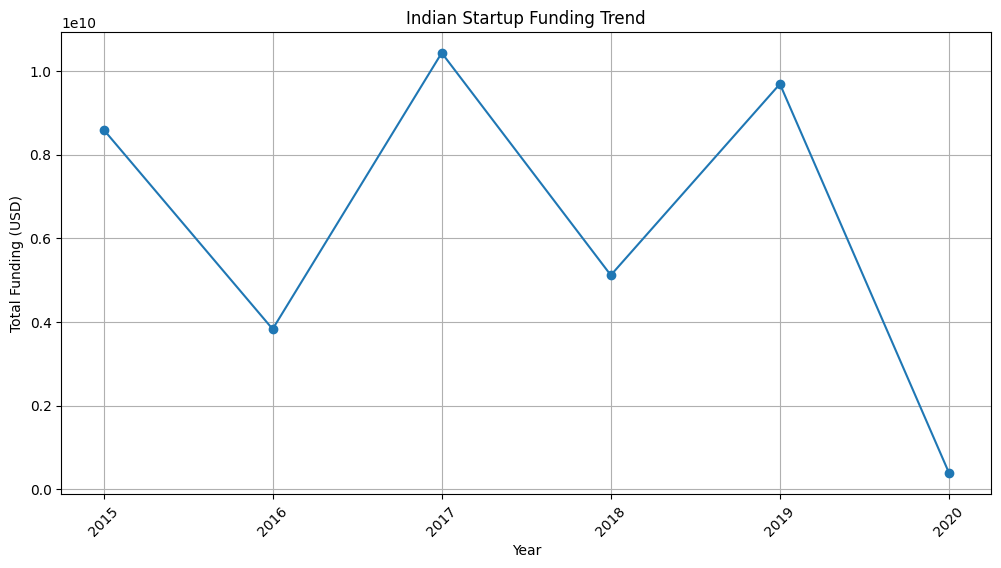

In [32]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_funding['year'],
    yearly_funding['total_funding'],
    marker='o'
)

plt.title('Indian Startup Funding Trend')
plt.xlabel('Year')
plt.ylabel('Total Funding (USD)')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

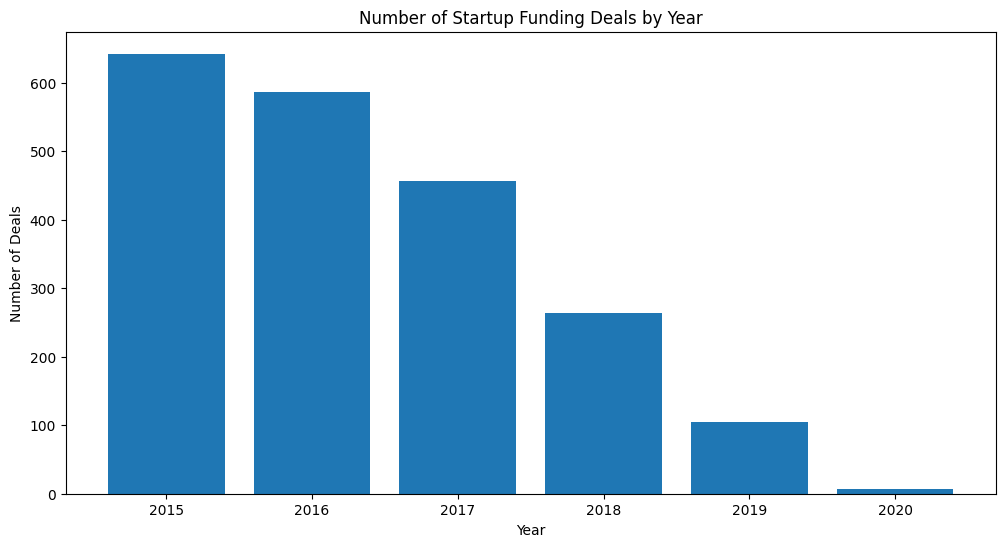

In [33]:
plt.figure(figsize=(12, 6))

plt.bar(
    yearly_funding['year'],
    yearly_funding['number_of_deals']
)

plt.title('Number of Startup Funding Deals by Year')
plt.xlabel('Year')
plt.ylabel('Number of Deals')

plt.show()

In [34]:
industry_analysis = (
    df.groupby('industry')
    .agg(
        total_funding=('amount_usd', 'sum'),
        number_of_deals=('amount_usd', 'count'),
        average_funding=('amount_usd', 'mean'),
        median_funding=('amount_usd', 'median')
    )
    .sort_values('total_funding', ascending=False)
)

industry_analysis.head(15)

,total_funding,number_of_deals,average_funding,median_funding
industry,,,,
E-Commerce,6293023064.54,159,39578761.412201,2700000.0
Consumer Internet,6253084245.0,589,10616441.842105,1000000.0
Transportation,3916632394.0,4,979158098.5,6524197.0
Technology,2229707930.0,310,7192606.225806,1500000.0
Finance,1971438000.0,57,34586631.578947,6240000.0
ECommerce,1878797608.0,37,50778313.72973,5000000.0
FinTech,1364911265.0,16,85306954.0625,10000000.0
Online Marketplace,700143000.0,2,350071500.0,350071500.0
E-Commerce & M-Commerce platform,680000000.0,1,680000000.0,680000000.0


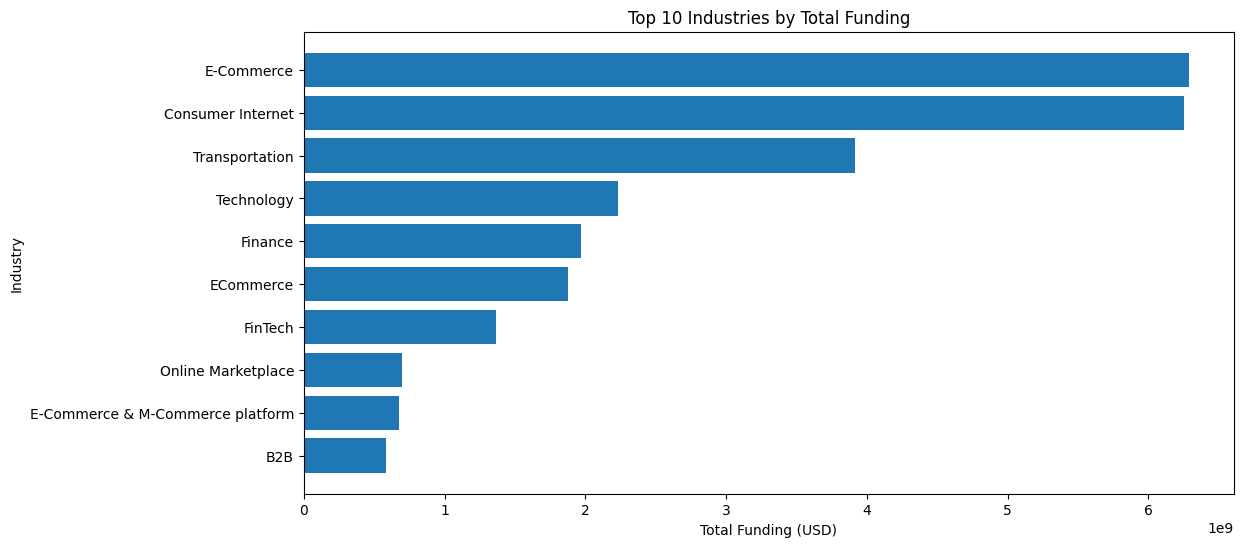

In [35]:
top_industries = industry_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_industries.index[::-1],
    top_industries['total_funding'][::-1]
)

plt.title('Top 10 Industries by Total Funding')
plt.xlabel('Total Funding (USD)')
plt.ylabel('Industry')

plt.show()


In [36]:
industry_deals = (
    df.groupby('industry')
    .size()
    .sort_values(ascending=False)
    .head(10)
)

industry_deals

industry
Consumer Internet    941
Technology           478
E-Commerce           226
Healthcare            70
Finance               62
ECommerce             61
Logistics             32
Education             24
Food & Beverage       23
EdTech                19
dtype: int64

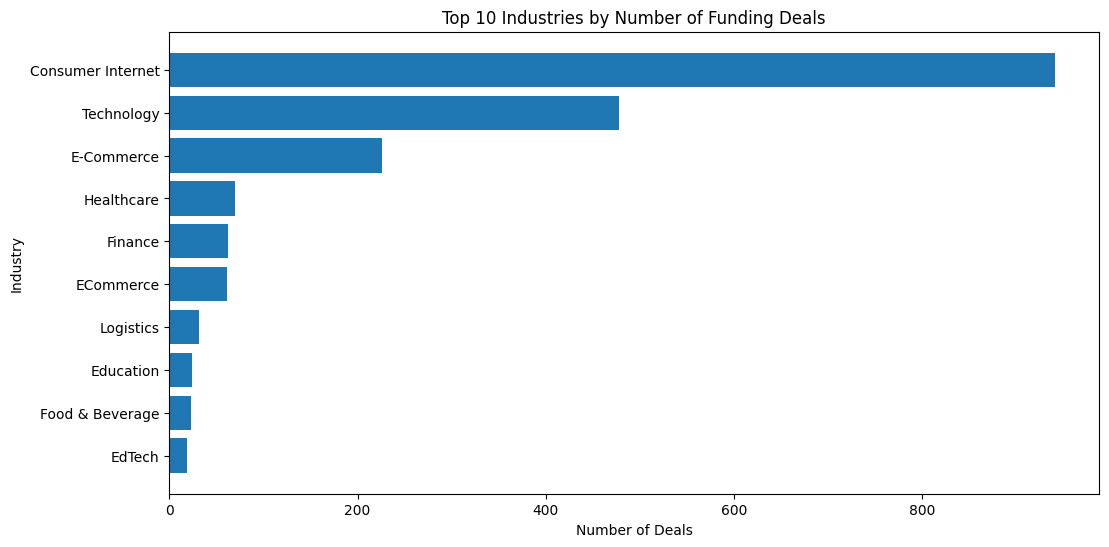

In [37]:
plt.figure(figsize=(12, 6))

plt.barh(
    industry_deals.index[::-1],
    industry_deals.values[::-1]
)

plt.title('Top 10 Industries by Number of Funding Deals')
plt.xlabel('Number of Deals')
plt.ylabel('Industry')

plt.show()

In [38]:
city_analysis = (
    df.groupby('city')
    .agg(
        total_funding=('amount_usd', 'sum'),
        number_of_deals=('amount_usd', 'count'),
        average_funding=('amount_usd', 'mean')
    )
    .sort_values('total_funding', ascending=False)
)

city_analysis.head(15)

,total_funding,number_of_deals,average_funding
city,,,
Bengaluru,18460166863.0,582,31718499.764605
Mumbai,4921185015.0,401,12272281.832918
Gurugram,3871228657.54,241,16063189.450373
New Delhi,3017816875.0,241,12522061.721992
Noida,1262864000.0,55,22961163.636364
Chennai,718767000.0,75,9583560.0
Pune,633082000.0,71,8916647.887324
Menlo Park,450000000.0,1,450000000.0
Hyderabad,401076230.0,72,5570503.194444


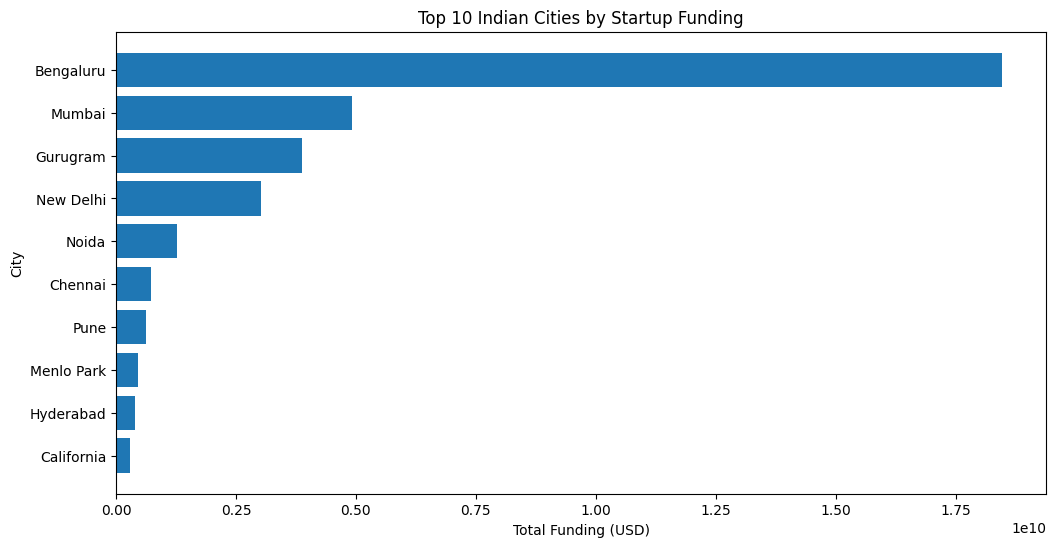

In [39]:
top_cities = city_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_cities.index[::-1],
    top_cities['total_funding'][::-1]
)

plt.title('Top 10 Indian Cities by Startup Funding')
plt.xlabel('Total Funding (USD)')
plt.ylabel('City')

plt.show()

In [40]:
investment_analysis = (
    df.groupby('investment_type')
    .agg(
        total_funding=('amount_usd', 'sum'),
        number_of_deals=('amount_usd', 'count'),
        average_funding=('amount_usd', 'mean'),
        median_funding=('amount_usd', 'median')
    )
    .sort_values('total_funding', ascending=False)
)

investment_analysis

,total_funding,number_of_deals,average_funding,median_funding
investment_type,,,,
Private Equity,26642318165.0,1066,24992793.775797,5925000.0
Series B,4799195735.0,20,239959786.75,15900000.0
Series D,1481799000.0,12,123483250.0,65000000.0
Series C,1044718394.0,14,74622742.428571,50000000.0
Funding Round,1000000000.0,1,1000000000.0,1000000000.0
Seed Funding,568628308.0,716,794173.614525,324500.0
Private Equity Round,506000000.0,4,126500000.0,150000000.0
Series G,231000000.0,1,231000000.0,231000000.0
Series A,203200000.0,22,9236363.636364,4250000.0


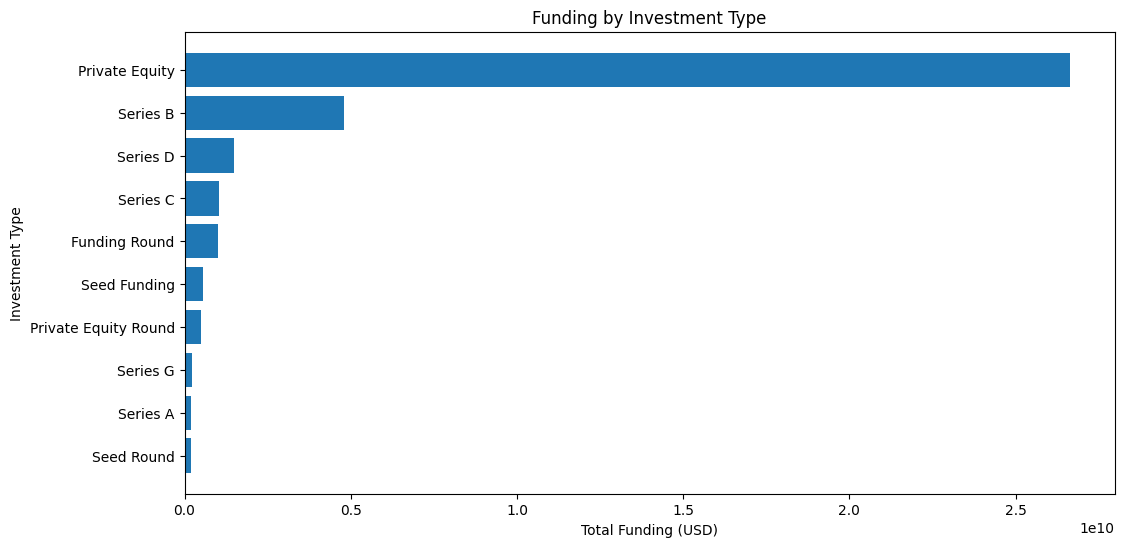

In [41]:
top_investment_types = investment_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_investment_types.index[::-1],
    top_investment_types['total_funding'][::-1]
)

plt.title('Funding by Investment Type')
plt.xlabel('Total Funding (USD)')
plt.ylabel('Investment Type')

plt.show()

In [42]:
largest_deals = (
    df[
        ['startup_name',
         'industry',
         'city',
         'investors',
         'investment_type',
         'amount_usd',
         'funding_date']
    ]
    .sort_values('amount_usd', ascending=False)
)

largest_deals.head(20)

,startup_name,industry,city,investors,investment_type,amount_usd,funding_date
60,Rapido Bike Taxi,Transportation,Bengaluru,Westbridge Capital,Series B,3900000000.0,2019-08-27
651,Flipkart,E-Commerce,Bengaluru,Softbank,Private Equity,2500000000.0,2017-08-11
966,Flipkart,E-Commerce,Bengaluru,"Microsoft, eBay, Tencent Holdings",Private Equity,1400000000.0,2017-03-21
830,Paytm,ECommerce,Bengaluru,SoftBank Group,Private Equity,1400000000.0,2017-05-18
31,Paytm,FinTech,Noida,Vijay Shekhar Sharma,Funding Round,1000000000.0,2019-11-25
2648,Flipkart.com,Online Marketplace,Bengaluru,Steadview Capital and existing investors,Private Equity,700000000.0,2015-07-28
2459,Paytm,E-Commerce & M-Commerce platform,New Delhi,"Alibaba Group, Ant Financial",Private Equity,680000000.0,2015-09-29
188,True North,Finance,Mumbai,<NA>,Private Equity,600000000.0,2018-08-30
33,Udaan,B2B,Bengaluru,"Altimeter Capital, DST Global",Series D,585000000.0,2019-10-02
2470,Snapdeal,Ecommerce Marketplace,New Delhi,"Alibaba, Foxconn, Softbank",Private Equity,500000000.0,2015-08-01


In [43]:
startup_deals = (
    df.groupby('startup_name')
    .agg(
        number_of_deals=('startup_name', 'count'),
        total_funding=('amount_usd', 'sum'),
        average_funding=('amount_usd', 'mean')
    )
    .sort_values('number_of_deals', ascending=False)
)

startup_deals.head(20)

,number_of_deals,total_funding,average_funding
startup_name,,,
Ola Cabs,8,669700000.0,95671428.571429
Swiggy,8,270500000.0,33812500.0
Paytm,7,3148950000.0,629790000.0
Meesho,6,189600000.0,47400000.0
Medinfi,6,780000.0,156000.0
NoBroker,6,71400000.0,17850000.0
Nykaa,6,214000000.0,42800000.0
UrbanClap,6,60700000.0,12140000.0
Flipkart,5,4059700000.0,811940000.0


In [44]:
df['investors'].value_counts()

investors
Undisclosed Investors                39
Undisclosed investors                30
Ratan Tata                           25
Indian Angel Network                 23
Kalaari Capital                      16
                                     ..
Kalaari Capital, Sequoia Capital      1
Asia Pacific Internet Group           1
KARSEMVEN Fund                        1
Exfinity Fund, GrowX Ventures.        1
UK based Group of Angel Investors     1
Name: count, Length: 2412, dtype: int64[pyarrow]

In [45]:
df['investors'].value_counts().head(20)

investors
Undisclosed Investors       39
Undisclosed investors       30
Ratan Tata                  25
Indian Angel Network        23
Kalaari Capital             16
Sequoia Capital             15
Group of Angel Investors    15
Accel Partners              12
Undisclosed Investor        12
Undisclosed                 11
Venture Catalysts           11
Brand Capital               11
undisclosed investors       11
SAIF Partners               10
RoundGlass Partners         10
Nexus Venture Partners       9
Info Edge (India) Ltd        9
Undisclosed investor         9
Blume Ventures               8
Tiger Global                 8
Name: count, dtype: int64[pyarrow]

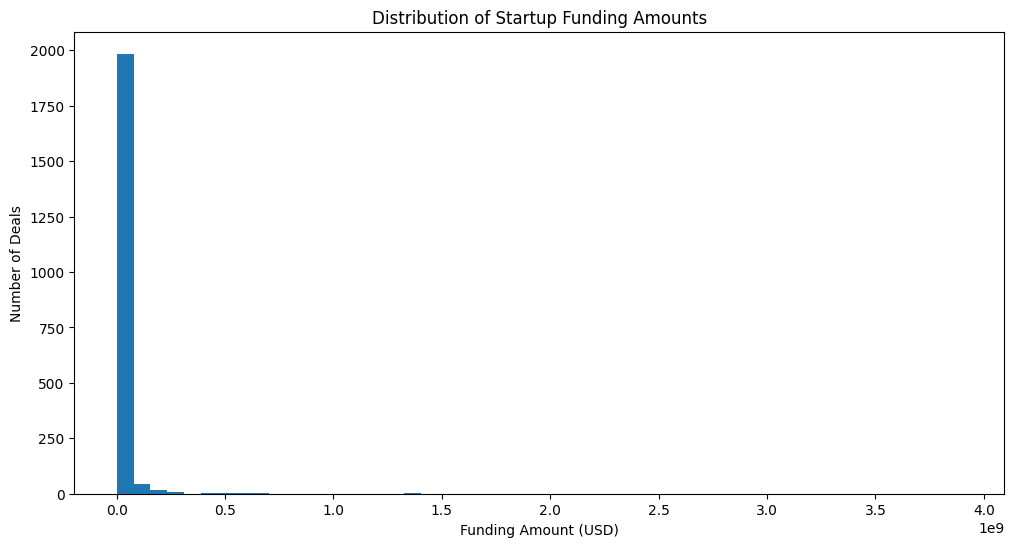

In [46]:
plt.figure(figsize=(12, 6))

plt.hist(
    df['amount_usd'].dropna(),
    bins=50
)

plt.title('Distribution of Startup Funding Amounts')
plt.xlabel('Funding Amount (USD)')
plt.ylabel('Number of Deals')

plt.show()

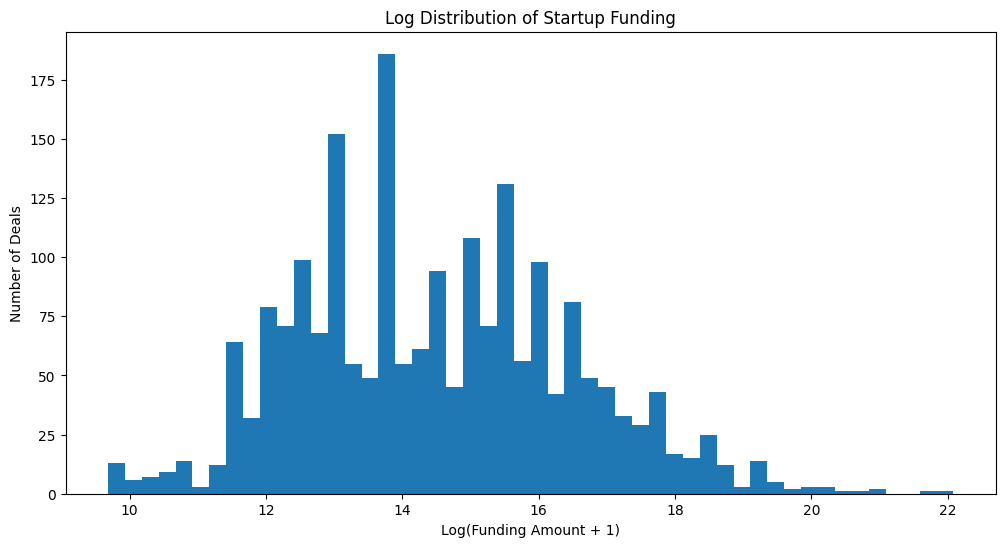

In [47]:
plt.figure(figsize=(12, 6))

plt.hist(
    np.log1p(df['amount_usd'].dropna()),
    bins=50
)

plt.title('Log Distribution of Startup Funding')
plt.xlabel('Log(Funding Amount + 1)')
plt.ylabel('Number of Deals')

plt.show()

In [48]:
investment_analysis = (
    df.groupby('investment_type')
    .agg(
        total_funding=('amount_usd', 'sum'),
        number_of_deals=('amount_usd', 'count'),
        average_funding=('amount_usd', 'mean'),
        median_funding=('amount_usd', 'median')
    )
    .sort_values('total_funding', ascending=False)
)

investment_analysis

,total_funding,number_of_deals,average_funding,median_funding
investment_type,,,,
Private Equity,26642318165.0,1066,24992793.775797,5925000.0
Series B,4799195735.0,20,239959786.75,15900000.0
Series D,1481799000.0,12,123483250.0,65000000.0
Series C,1044718394.0,14,74622742.428571,50000000.0
Funding Round,1000000000.0,1,1000000000.0,1000000000.0
Seed Funding,568628308.0,716,794173.614525,324500.0
Private Equity Round,506000000.0,4,126500000.0,150000000.0
Series G,231000000.0,1,231000000.0,231000000.0
Series A,203200000.0,22,9236363.636364,4250000.0


In [49]:
investment_analysis.head(15)

,total_funding,number_of_deals,average_funding,median_funding
investment_type,,,,
Private Equity,26642318165.0,1066,24992793.775797,5925000.0
Series B,4799195735.0,20,239959786.75,15900000.0
Series D,1481799000.0,12,123483250.0,65000000.0
Series C,1044718394.0,14,74622742.428571,50000000.0
Funding Round,1000000000.0,1,1000000000.0,1000000000.0
Seed Funding,568628308.0,716,794173.614525,324500.0
Private Equity Round,506000000.0,4,126500000.0,150000000.0
Series G,231000000.0,1,231000000.0,231000000.0
Series A,203200000.0,22,9236363.636364,4250000.0


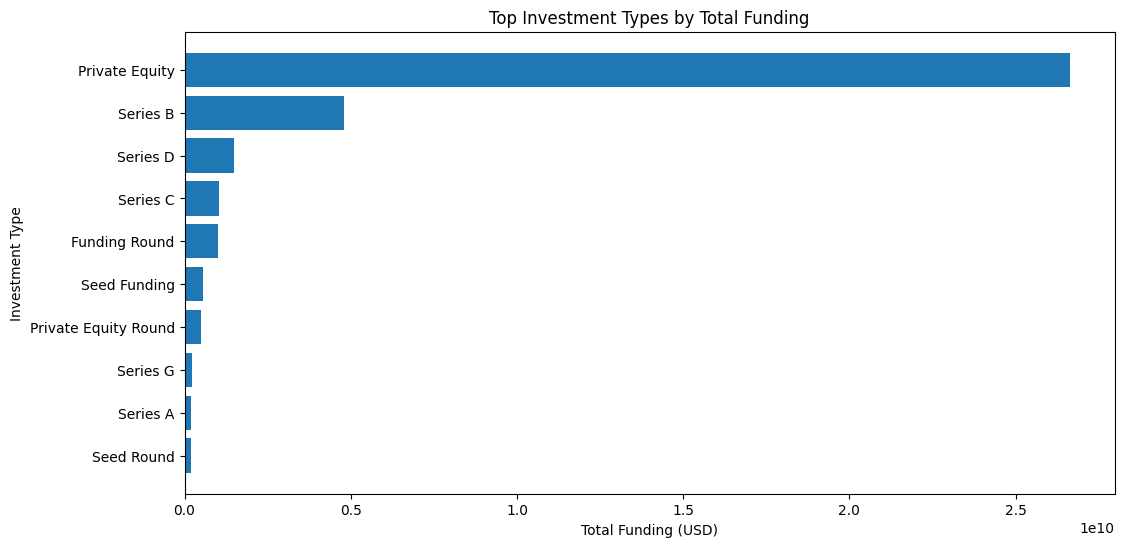

In [50]:
top_investment_types = investment_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_investment_types.index[::-1],
    top_investment_types['total_funding'][::-1]
)

plt.title('Top Investment Types by Total Funding')
plt.xlabel('Total Funding (USD)')
plt.ylabel('Investment Type')

plt.show()

In [51]:
largest_deals = (
    df[
        [
            'startup_name',
            'industry',
            'city',
            'investors',
            'investment_type',
            'amount_usd',
            'funding_date'
        ]
    ]
    .sort_values(
        'amount_usd',
        ascending=False
    )
)

largest_deals.head(20)

,startup_name,industry,city,investors,investment_type,amount_usd,funding_date
60,Rapido Bike Taxi,Transportation,Bengaluru,Westbridge Capital,Series B,3900000000.0,2019-08-27
651,Flipkart,E-Commerce,Bengaluru,Softbank,Private Equity,2500000000.0,2017-08-11
966,Flipkart,E-Commerce,Bengaluru,"Microsoft, eBay, Tencent Holdings",Private Equity,1400000000.0,2017-03-21
830,Paytm,ECommerce,Bengaluru,SoftBank Group,Private Equity,1400000000.0,2017-05-18
31,Paytm,FinTech,Noida,Vijay Shekhar Sharma,Funding Round,1000000000.0,2019-11-25
2648,Flipkart.com,Online Marketplace,Bengaluru,Steadview Capital and existing investors,Private Equity,700000000.0,2015-07-28
2459,Paytm,E-Commerce & M-Commerce platform,New Delhi,"Alibaba Group, Ant Financial",Private Equity,680000000.0,2015-09-29
188,True North,Finance,Mumbai,<NA>,Private Equity,600000000.0,2018-08-30
33,Udaan,B2B,Bengaluru,"Altimeter Capital, DST Global",Series D,585000000.0,2019-10-02
2470,Snapdeal,Ecommerce Marketplace,New Delhi,"Alibaba, Foxconn, Softbank",Private Equity,500000000.0,2015-08-01


In [52]:
startup_analysis = (
    df.groupby('startup_name')
    .agg(
        number_of_deals=('startup_name', 'count'),
        total_funding=('amount_usd', 'sum'),
        average_funding=('amount_usd', 'mean'),
        median_funding=('amount_usd', 'median')
    )
    .sort_values(
        'number_of_deals',
        ascending=False
    )
)

startup_analysis.head(20)

,number_of_deals,total_funding,average_funding,median_funding
startup_name,,,,
Ola Cabs,8,669700000.0,95671428.571429,36000000.0
Swiggy,8,270500000.0,33812500.0,15750000.0
Paytm,7,3148950000.0,629790000.0,680000000.0
Meesho,6,189600000.0,47400000.0,30750000.0
Medinfi,6,780000.0,156000.0,125000.0
NoBroker,6,71400000.0,17850000.0,8700000.0
Nykaa,6,214000000.0,42800000.0,12300000.0
UrbanClap,6,60700000.0,12140000.0,10000000.0
Flipkart,5,4059700000.0,811940000.0,71000000.0


In [53]:
top_funded_startups = (
    startup_analysis
    .sort_values(
        'total_funding',
        ascending=False
    )
)

top_funded_startups.head(20)

,number_of_deals,total_funding,average_funding,median_funding
startup_name,,,,
Flipkart,5,4059700000.0,811940000.0,71000000.0
Rapido Bike Taxi,1,3900000000.0,3900000000.0,3900000000.0
Paytm,7,3148950000.0,629790000.0,680000000.0
Ola,4,984500000.0,246125000.0,217250000.0
Udaan,4,870000000.0,217500000.0,137500000.0
Flipkart.com,1,700000000.0,700000000.0,700000000.0
Snapdeal,2,700000000.0,350000000.0,350000000.0
Ola Cabs,8,669700000.0,95671428.571429,36000000.0
True North,1,600000000.0,600000000.0,600000000.0


In [54]:
total_funding = df['amount_usd'].sum()

top_10_funding = (
    df.nlargest(10, 'amount_usd')['amount_usd'].sum()
)

top_20_funding = (
    df.nlargest(20, 'amount_usd')['amount_usd'].sum()
)

top_50_funding = (
    df.nlargest(50, 'amount_usd')['amount_usd'].sum()
)

print("Total Funding:", total_funding)
print("Top 10 share:", top_10_funding / total_funding * 100)
print("Top 20 share:", top_20_funding / total_funding * 100)
print("Top 50 share:", top_50_funding / total_funding * 100)

Total Funding: 38057737864.22
Top 10 share: 34.85493553853892
Top 20 share: 43.63895736329094
Top 50 share: 57.43693983596155


In [55]:
industry_analysis['funding_per_deal'] = (
    industry_analysis['total_funding'] /
    industry_analysis['number_of_deals']
)

In [56]:
industry_analysis.sort_values(
    'funding_per_deal',
    ascending=False
).head(15)

,total_funding,number_of_deals,average_funding,median_funding,funding_per_deal
industry,,,,,
Transportation,3916632394.0,4,979158098.5,6524197.0,979158098.5
E-Commerce & M-Commerce platform,680000000.0,1,680000000.0,680000000.0,680000000.0
Car Aggregator & Retail Mobile App,500000000.0,1,500000000.0,500000000.0,500000000.0
Ecommerce Marketplace,500000000.0,1,500000000.0,500000000.0,500000000.0
Cab Aggregator,400000000.0,1,400000000.0,400000000.0,400000000.0
Online Marketplace,700143000.0,2,350071500.0,350071500.0,350071500.0
Automation,300000000.0,1,300000000.0,300000000.0,300000000.0
B2B,587000000.0,2,293500000.0,293500000.0,293500000.0
Cab rental Mobile app,225000000.0,1,225000000.0,225000000.0,225000000.0


In [57]:
industry_analysis[
    industry_analysis['number_of_deals'] >= 10
].sort_values(
    'funding_per_deal',
    ascending=False
).head(15)

,total_funding,number_of_deals,average_funding,median_funding,funding_per_deal
industry,,,,,
FinTech,1364911265.0,16,85306954.0625,10000000.0,85306954.0625
ECommerce,1878797608.0,37,50778313.72973,5000000.0,50778313.72973
E-Commerce,6293023064.54,159,39578761.412201,2700000.0,39578761.412201
Finance,1971438000.0,57,34586631.578947,6240000.0,34586631.578947
Education,301143000.0,19,15849631.578947,1500000.0,15849631.578947
EdTech,191496065.0,17,11264474.411765,772500.0,11264474.411765
Consumer Internet,6253084245.0,589,10616441.842105,1000000.0,10616441.842105
Logistics,242845000.0,23,10558478.26087,6000000.0,10558478.26087
Healthcare,381218000.0,44,8664045.454545,2550000.0,8664045.454545


In [58]:
print("Missing investors:", df['investors'].isna().sum())
print("Total rows:", len(df))

Missing investors: 24
Total rows: 3044


In [59]:
df['investors'].value_counts().head(20)

investors
Undisclosed Investors       39
Undisclosed investors       30
Ratan Tata                  25
Indian Angel Network        23
Kalaari Capital             16
Sequoia Capital             15
Group of Angel Investors    15
Accel Partners              12
Undisclosed Investor        12
Undisclosed                 11
Venture Catalysts           11
Brand Capital               11
undisclosed investors       11
SAIF Partners               10
RoundGlass Partners         10
Nexus Venture Partners       9
Info Edge (India) Ltd        9
Undisclosed investor         9
Blume Ventures               8
Tiger Global                 8
Name: count, dtype: int64[pyarrow]

In [60]:
investor_df = df[
    ['startup_name', 'investors', 'amount_usd', 'funding_date', 'industry', 'city']
].copy()

In [61]:
investor_df = investor_df.dropna(subset=['investors'])

In [62]:
investor_df['investor'] = investor_df['investors'].str.split(',')

In [63]:
investor_df = investor_df.explode('investor')

In [64]:
investor_df['investor'] = (
    investor_df['investor']
    .astype('string')
    .str.strip()
)

In [65]:
investor_df.head(20)

,startup_name,investors,amount_usd,funding_date,industry,city,investor
0,BYJU’S,Tiger Global Management,200000000.0,2020-01-09,E-Tech,Bengaluru,Tiger Global Management
1,Shuttl,Susquehanna Growth Equity,8048394.0,2020-01-13,Transportation,Gurugram,Susquehanna Growth Equity
2,Mamaearth,Sequoia Capital India,18358860.0,2020-01-09,E-commerce,Bengaluru,Sequoia Capital India
3,https://www.wealthbucket.in/,Vinod Khatumal,3000000.0,2020-01-02,FinTech,New Delhi,Vinod Khatumal
4,Fashor,Sprout Venture Partners,1800000.0,2020-01-02,Fashion and Apparel,Mumbai,Sprout Venture Partners
5,Pando,Chiratae Ventures,9000000.0,2020-01-13,Logistics,Chennai,Chiratae Ventures
6,Zomato,Ant Financial,150000000.0,2020-01-10,Hospitality,Gurugram,Ant Financial
7,Ecozen,Sathguru Catalyzer Advisors,6000000.0,2019-12-12,Technology,Pune,Sathguru Catalyzer Advisors
8,CarDekho,Ping An Global Voyager Fund,70000000.0,2019-12-06,E-Commerce,Gurugram,Ping An Global Voyager Fund
9,Dhruva Space,"Mumbai Angels, Ravikanth Reddy",50000000.0,2019-12-03,Aerospace,Bengaluru,Mumbai Angels


In [66]:
top_investors_deals = (
    investor_df
    .groupby('investor')
    .size()
    .sort_values(ascending=False)
)

top_investors_deals.head(20)

investor
Sequoia Capital           72
Accel Partners            68
                          58
Kalaari Capital           50
SAIF Partners             47
Blume Ventures            47
Indian Angel Network      41
Undisclosed Investors     39
Ratan Tata                31
Undisclosed investors     31
Nexus Venture Partners    30
IDG Ventures              28
Rajan Anandan             28
Tiger Global              27
Kae Capital               24
Matrix Partners           24
Sequoia India             22
LetsVenture               22
India Quotient            22
500 Startups              21
dtype: int64

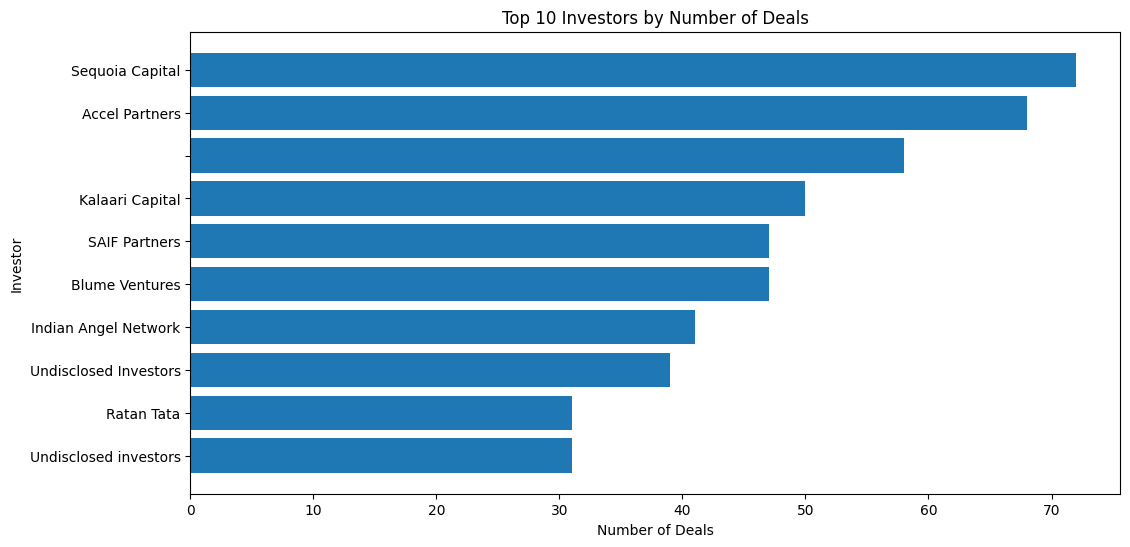

In [67]:
top_10_investors = top_investors_deals.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_investors.index[::-1],
    top_10_investors.values[::-1]
)

plt.title('Top 10 Investors by Number of Deals')
plt.xlabel('Number of Deals')
plt.ylabel('Investor')

plt.show()

In [68]:
investor_df = df[
    ['startup_name', 'investors', 'amount_usd',
     'funding_date', 'industry', 'city']
].copy()

investor_df = investor_df.dropna(subset=['investors'])

investor_df['investor'] = investor_df['investors'].str.split(',')

investor_df['investor_count'] = investor_df['investor'].str.len()

In [69]:
investor_df.head()

,startup_name,investors,amount_usd,funding_date,industry,city,investor,investor_count
0,BYJU’S,Tiger Global Management,200000000.0,2020-01-09,E-Tech,Bengaluru,[Tiger Global Management],1
1,Shuttl,Susquehanna Growth Equity,8048394.0,2020-01-13,Transportation,Gurugram,[Susquehanna Growth Equity],1
2,Mamaearth,Sequoia Capital India,18358860.0,2020-01-09,E-commerce,Bengaluru,[Sequoia Capital India],1
3,https://www.wealthbucket.in/,Vinod Khatumal,3000000.0,2020-01-02,FinTech,New Delhi,[Vinod Khatumal],1
4,Fashor,Sprout Venture Partners,1800000.0,2020-01-02,Fashion and Apparel,Mumbai,[Sprout Venture Partners],1


In [70]:
investor_df = investor_df.explode('investor')

investor_df['investor'] = (
    investor_df['investor']
    .astype('string')
    .str.strip()
)

In [71]:
investor_df['allocated_funding'] = (
    investor_df['amount_usd'] /
    investor_df['investor_count']
)

In [72]:
investor_analysis = (
    investor_df
    .groupby('investor')
    .agg(
        number_of_deals=('startup_name', 'count'),
        allocated_funding=('allocated_funding', 'sum'),
        average_deal=('allocated_funding', 'mean')
    )
    .sort_values(
        'allocated_funding',
        ascending=False
    )
)

In [73]:
investor_analysis.head(20)

,number_of_deals,allocated_funding,average_deal
investor,,,
Westbridge Capital,1,3900000000.0,3900000000.0
Softbank,6,2822916666.666667,470486111.111111
SoftBank Group,6,1655333333.333333,275888888.888889
Vijay Shekhar Sharma,12,1001101190.47619,143014455.782313
Steadview Capital and existing investors,1,700000000.0,700000000.0
Tiger Global,27,632175000.0,23413888.888889
Sequoia Capital,72,625860238.095238,9203827.030812
SoftBank Vision Fund,3,593500000.0,197833333.333333
Tencent Holdings,3,536666666.666667,178888888.888889


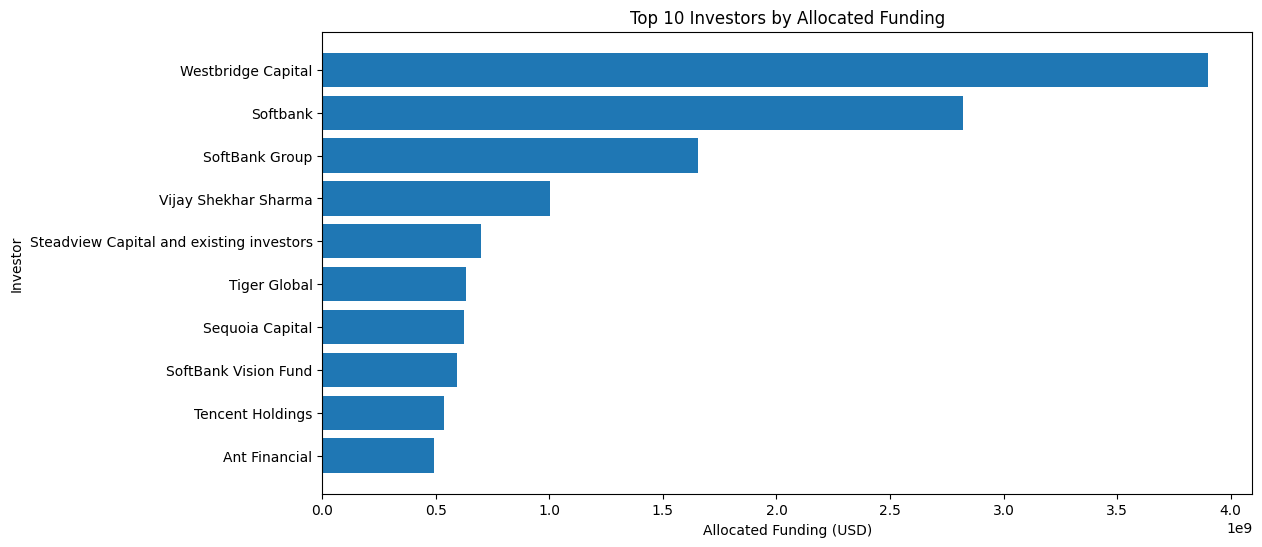

In [74]:
top_funded_investors = investor_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_funded_investors.index[::-1],
    top_funded_investors['allocated_funding'][::-1]
)

plt.title('Top 10 Investors by Allocated Funding')
plt.xlabel('Allocated Funding (USD)')
plt.ylabel('Investor')

plt.show()

In [75]:
investor_industry = (
    investor_df
    .groupby(['investor', 'industry'])
    .agg(
        deals=('startup_name', 'count'),
        funding=('allocated_funding', 'sum')
    )
    .reset_index()
)

In [76]:
investor_industry.sort_values(
    'funding',
    ascending=False
).head(20)

,investor,industry,deals,funding
4384,Westbridge Capital,Transportation,1,3900000000.0
3700,Softbank,E-Commerce,1,2500000000.0
3690,SoftBank Group,ECommerce,1,1400000000.0
4274,Vijay Shekhar Sharma,FinTech,1,1000000000.0
3759,Steadview Capital and existing investors,Online Marketplace,1,700000000.0
2357,Microsoft,E-Commerce,1,466666666.666667
4583,eBay,E-Commerce,1,466666666.666667
3918,Tencent Holdings,E-Commerce,1,466666666.666667
694,Bennett Coleman and Company Ltd (BCCL),Health and Wellness,1,450000000.0
246,Alibaba Group,E-Commerce & M-Commerce platform,1,340000000.0


In [77]:
investor_city = (
    investor_df
    .groupby(['investor', 'city'])
    .agg(
        deals=('startup_name', 'count'),
        funding=('allocated_funding', 'sum')
    )
    .reset_index()
)

In [78]:
investor_city.sort_values(
    'funding',
    ascending=False
).head(20)

,investor,city,deals,funding
3912,Westbridge Capital,Bengaluru,1,3900000000.0
3292,Softbank,Bengaluru,2,2556250000.0
3283,SoftBank Group,Bengaluru,2,1483333333.333333
3809,Vijay Shekhar Sharma,Noida,2,1000125000.0
3347,Steadview Capital and existing investors,Bengaluru,1,700000000.0
3500,Tencent Holdings,Bengaluru,2,501666666.666667
856,DST Global,Bengaluru,4,478166666.666667
2123,Microsoft,Bengaluru,1,466666666.666667
4097,eBay,Bengaluru,1,466666666.666667
604,Bennett Coleman and Company Ltd (BCCL),Menlo Park,1,450000000.0


In [79]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [80]:
df[df.duplicated(keep=False)].sort_values(
    by=['startup_name', 'funding_date']
).head(20)

,Sr No,funding_date,startup_name,industry,sub_vertical,city,investors,investment_type,amount_usd,remarks,year,month,month_name,quarter


In [81]:
missing = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
)

missing

amount_usd         979
sub_vertical       936
city               180
industry           171
investors           24
funding_date         8
month_name           8
quarter              8
month                8
year                 8
investment_type      4
Sr No                0
startup_name         0
remarks              0
dtype: int64

In [82]:
missing_pct = (
    df.isna().mean() * 100
).sort_values(ascending=False)

missing_summary = pd.DataFrame({
    'missing_count': missing,
    'missing_percentage': missing_pct.round(2)
})

missing_summary

,missing_count,missing_percentage
amount_usd,979,32.16
sub_vertical,936,30.75
city,180,5.91
industry,171,5.62
investors,24,0.79
funding_date,8,0.26
month_name,8,0.26
quarter,8,0.26
month,8,0.26
year,8,0.26


In [83]:
df.dtypes

Sr No                       int64
funding_date       datetime64[us]
startup_name               string
industry                   string
sub_vertical               string
city                       string
investors                  string
investment_type            string
amount_usd                Float64
remarks                    string
year                      float64
month                     float64
month_name                    str
quarter                   float64
dtype: object

In [84]:
Q1 = df['amount_usd'].quantile(0.25)
Q3 = df['amount_usd'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['amount_usd'] < lower_bound) |
    (df['amount_usd'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("Upper Bound:", upper_bound)
print("Number of outliers:", len(outliers))

Q1: 470000.0
Q3: 8000000.0
Upper Bound: 19295000.0
Number of outliers: 283


In [85]:
print(
    "Zero funding:",
    (df['amount_usd'] == 0).sum()
)

print(
    "Negative funding:",
    (df['amount_usd'] < 0).sum()
)

Zero funding: 0
Negative funding: 0


In [86]:
df['city'].value_counts(dropna=False).head(50)

city
Bengaluru              841
Mumbai                 567
New Delhi              421
Gurugram               337
<NA>                   180
Pune                   105
Hyderabad               99
Chennai                 97
Noida                   92
Ahmedabad               38
Delhi                   34
Jaipur                  30
Kolkata                 21
Indore                  13
Chandigarh              11
Goa                     10
Vadodara                10
Singapore                8
Coimbatore               5
Kanpur                   4
Pune / US                4
\\xc2\\xa0Gurgaon        4
Faridabad                3
Bhopal                   3
Nagpur                   3
\\xc2\\xa0New Delhi      3
San Francisco            2
Kormangala               2
Mumbai/Bengaluru         2
India/US                 2
Ahemadabad               2
Udaipur                  2
Surat                    2
Trivandrum               2
Gwalior                  2
Udupi                    2
Kochi                  

In [87]:
df['startup_name'].value_counts().head(30)

startup_name
Ola Cabs         8
Swiggy           8
Paytm            7
Meesho           6
NoBroker         6
Nykaa            6
Medinfi          6
UrbanClap        6
Uniphore         5
Grofers          5
Moglix           5
Toppr            5
Capital Float    5
Flipkart         5
Jugnoo           5
Shuttl           4
Zomato           4
CarDekho         4
Rivigo           4
Healthians       4
Licious          4
Aye Finance      4
Udaan            4
Indus OS         4
Unacademy        4
HealthifyMe      4
EazyDiner        4
Zoctr            4
Coverfox         4
RailYatri        4
Name: count, dtype: int64[pyarrow]

In [88]:
df_clean = df.copy()

In [89]:
text_columns = [
    'startup_name',
    'industry',
    'sub_vertical',
    'city',
    'investors',
    'investment_type',
    'remarks'
]

for col in text_columns:
    df_clean[col] = (
        df_clean[col]
        .astype('string')
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
    )

In [90]:
categorical_columns = [
    'industry',
    'sub_vertical',
    'city',
    'investors',
    'investment_type'
]

for col in categorical_columns:
    df_clean[col] = df_clean[col].fillna('Unknown')

In [91]:
df_clean[categorical_columns].isna().sum()

industry           0
sub_vertical       0
city               0
investors          0
investment_type    0
dtype: int64

In [92]:
df_clean['city'] = (
    df_clean['city']
    .str.replace(r'\\xc2\\xa0', '', regex=True)
    .str.strip()
)

In [93]:
city_mapping = {
    'Bangalore': 'Bengaluru',
    'Bengaluru ': 'Bengaluru',
    'Delhi': 'New Delhi',
    'Gurgaon': 'Gurugram',
    'Ahemadabad': 'Ahmedabad',
    'Kormangala': 'Bengaluru'
}

df_clean['city'] = df_clean['city'].replace(city_mapping)

In [94]:
df_clean['city'].value_counts().head(30)

city
Bengaluru              843
Mumbai                 567
New Delhi              455
Gurugram               337
Unknown                180
Pune                   105
Hyderabad               99
Chennai                 97
Noida                   92
Ahmedabad               40
Jaipur                  30
Kolkata                 21
Indore                  13
Chandigarh              11
Goa                     10
Vadodara                10
Singapore                8
Coimbatore               5
Kanpur                   4
Pune / US                4
\\xc2\\xa0Gurgaon        4
Faridabad                3
Bhopal                   3
Nagpur                   3
\\xc2\\xa0New Delhi      3
San Francisco            2
Mumbai/Bengaluru         2
India/US                 2
Udaipur                  2
Surat                    2
Name: count, dtype: int64[pyarrow]

In [95]:
industry_counts = (
    df_clean['industry']
    .value_counts()
)

industry_counts

industry
Consumer Internet             941
Technology                    478
E-Commerce                    226
Unknown                       171
Healthcare                     70
                             ... 
Startup Analytics platform      1
Mobile Food Ordering app        1
Financial Markets Software      1
Hiring Analytics platform       1
Online Travel Marketplace       1
Name: count, Length: 815, dtype: int64[pyarrow]

In [96]:
print(industry_counts.to_string())

industry
Consumer Internet                                             941
Technology                                                    478
E-Commerce                                                    226
Unknown                                                       171
Healthcare                                                     70
Finance                                                        62
ECommerce                                                      61
Logistics                                                      32
Education                                                      24
Food & Beverage                                                23
EdTech                                                         19
FinTech                                                        16
E-commerce                                                     12
IT                                                              8
Food and Beverage                                               6
R

In [97]:
investment_type_counts = (
    df_clean['investment_type']
    .value_counts()
)

investment_type_counts

investment_type
Private Equity                 1356
Seed Funding                   1355
Seed/Angel Funding              130
Seed\\nFunding                   30
Debt Funding                     25
Series A                         24
Series B                         20
Series C                         14
Series D                         12
Angel / Seed Funding              8
Seed Round                        7
Private Equity Round              4
Seed                              4
Unknown                           4
Pre-Series A                      4
Seed / Angle Funding              3
Series F                          2
Series E                          2
Corporate Round                   2
Venture Round                     2
pre-Series A                      2
Equity                            2
Pre-series A                      1
Series G                          1
Series H                          1
Venture                           1
Funding Round                     1
Maiden Round

In [98]:
df_clean['year'] = df_clean['funding_date'].dt.year
df_clean['month'] = df_clean['funding_date'].dt.month
df_clean['month_name'] = df_clean['funding_date'].dt.month_name()
df_clean['quarter'] = df_clean['funding_date'].dt.quarter

In [99]:
df_clean[
    ['funding_date', 'year', 'month', 'month_name', 'quarter']
].head(10)

,funding_date,year,month,month_name,quarter
0,2020-01-09,2020.0,1.0,January,1.0
1,2020-01-13,2020.0,1.0,January,1.0
2,2020-01-09,2020.0,1.0,January,1.0
3,2020-01-02,2020.0,1.0,January,1.0
4,2020-01-02,2020.0,1.0,January,1.0
5,2020-01-13,2020.0,1.0,January,1.0
6,2020-01-10,2020.0,1.0,January,1.0
7,2019-12-12,2019.0,12.0,December,4.0
8,2019-12-06,2019.0,12.0,December,4.0
9,2019-12-03,2019.0,12.0,December,4.0


In [100]:
df_clean['funding_status'] = df_clean['amount_usd'].apply(
    lambda x: 'Available' if pd.notna(x) else 'Missing'
)

In [101]:
df_clean['funding_status'].value_counts()

funding_status
Available    2065
Missing       979
Name: count, dtype: int64

In [102]:
international_keywords = [
    'US',
    'USA',
    'Singapore',
    'Bangkok',
    'SFO',
    'San Francisco',
    'San Jose',
    'Palo Alto',
    'Menlo Park',
    'California',
    'Santa Monica'
]

def classify_location(city):
    if city == 'Unknown':
        return 'Unknown'
    
    if '/' in city:
        return 'Multiple Locations'
    
    for keyword in international_keywords:
        if keyword.lower() in city.lower():
            return 'International'
    
    return 'India'

In [103]:
df_clean['location_type'] = df_clean['city'].apply(
    classify_location
)

In [104]:
df_clean['location_type'].value_counts()

location_type
India                 2809
Unknown                180
Multiple Locations      38
International           17
Name: count, dtype: int64

In [105]:
def funding_category(amount):
    if pd.isna(amount):
        return 'Unknown'
    elif amount < 1_000_000:
        return 'Below $1M'
    elif amount < 10_000_000:
        return '$1M - $10M'
    elif amount < 50_000_000:
        return '$10M - $50M'
    elif amount < 100_000_000:
        return '$50M - $100M'
    else:
        return '$100M+'

In [106]:
df_clean['funding_category'] = (
    df_clean['amount_usd']
    .apply(funding_category)
)

In [107]:
df_clean['funding_category'].value_counts()

funding_category
Unknown         979
$1M - $10M      827
Below $1M       750
$10M - $50M     346
$100M+           73
$50M - $100M     69
Name: count, dtype: int64

In [108]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Sr No             3044 non-null   int64         
 1   funding_date      3036 non-null   datetime64[us]
 2   startup_name      3044 non-null   string        
 3   industry          3044 non-null   string        
 4   sub_vertical      3044 non-null   string        
 5   city              3044 non-null   string        
 6   investors         3044 non-null   string        
 7   investment_type   3044 non-null   string        
 8   amount_usd        2065 non-null   Float64       
 9   remarks           3044 non-null   string        
 10  year              3036 non-null   float64       
 11  month             3036 non-null   float64       
 12  month_name        3036 non-null   str           
 13  quarter           3036 non-null   float64       
 14  funding_status    3044 non-null   s

In [109]:
df_clean.isna().sum()

Sr No                 0
funding_date          8
startup_name          0
industry              0
sub_vertical          0
city                  0
investors             0
investment_type       0
amount_usd          979
remarks               0
year                  8
month                 8
month_name            8
quarter               8
funding_status        0
location_type         0
funding_category      0
dtype: int64

In [110]:
df_clean.shape

(3044, 17)

In [111]:
df_clean.head()

,Sr No,funding_date,startup_name,industry,sub_vertical,city,investors,investment_type,amount_usd,remarks,year,month,month_name,quarter,funding_status,location_type,funding_category
0,1,2020-01-09,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,200000000.0,Not Available,2020.0,1.0,January,1.0,Available,India,$100M+
1,2,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurugram,Susquehanna Growth Equity,Series C,8048394.0,Not Available,2020.0,1.0,January,1.0,Available,India,$1M - $10M
2,3,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,18358860.0,Not Available,2020.0,1.0,January,1.0,Available,India,$10M - $50M
3,4,2020-01-02,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,3000000.0,Not Available,2020.0,1.0,January,1.0,Available,India,$1M - $10M
4,5,2020-01-02,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,1800000.0,Not Available,2020.0,1.0,January,1.0,Available,India,$1M - $10M


In [112]:
# Standardize industry names
industry_mapping = {
    'E-Commerce': 'E-Commerce',
    'ECOMmerce': 'E-Commerce',
    'E-commerce': 'E-Commerce',
    'Ecommerce': 'E-Commerce',
    'Ecommerce Marketplace': 'E-Commerce',

    'Food & Beverage': 'Food & Beverage',
    'Food and Beverage': 'Food & Beverage',

    'FinTech': 'FinTech',
    'EdTech': 'EdTech',

    'Healthcare': 'Healthcare',
    'Health Care': 'Healthcare',

    'IT': 'Technology'
}

df_clean['industry'] = (
    df_clean['industry']
    .replace(industry_mapping)
)

In [113]:
df_clean['industry'].value_counts().head(30)

industry
Consumer Internet            941
Technology                   486
E-Commerce                   239
Unknown                      171
Healthcare                    72
Finance                       62
ECommerce                     61
Logistics                     32
Food & Beverage               29
Education                     24
EdTech                        19
FinTech                       16
Real Estate                    6
Others                         6
Health and Wellness            5
Logistics Tech                 5
Online Education Platform      5
Online Food Delivery           5
Transportation                 4
Transport                      4
SaaS                           3
Information Technology         3
Services                       3
Automobile                     3
Social Media                   3
Food                           3
Food & Beverages               3
Food and Beverages             3
FMCG                           3
Food Delivery Platform         3
N

In [114]:
def classify_funding_stage(value):

    if pd.isna(value):
        return 'Unknown'

    value = str(value).strip().lower()

    # Private Equity
    if 'private equity' in value or 'privateequity' in value:
        return 'Private Equity'

    # Seed / Angel
    if 'seed' in value or 'angel' in value:
        return 'Seed / Angel'

    # Series
    if 'series a' in value:
        return 'Series A'

    if 'series b' in value:
        return 'Series B'

    if 'series c' in value:
        return 'Series C'

    if 'series d' in value:
        return 'Series D'

    if 'series e' in value:
        return 'Series E'

    if 'series f' in value:
        return 'Series F'

    if 'series g' in value:
        return 'Series G'

    if 'series h' in value:
        return 'Series H'

    if 'series j' in value:
        return 'Series J'

    # Debt
    if 'debt' in value:
        return 'Debt'

    # Equity
    if 'equity' in value:
        return 'Equity'

    # Venture
    if 'venture' in value:
        return 'Venture'

    # Corporate
    if 'corporate' in value:
        return 'Corporate'

    # Funding round
    if 'funding round' in value or 'round' in value:
        return 'Other Funding Round'

    return 'Other'

In [115]:
df_clean['funding_stage'] = (
    df_clean['investment_type']
    .apply(classify_funding_stage)
)

In [116]:
df_clean['funding_stage'].value_counts()

funding_stage
Seed / Angel           1542
Private Equity         1361
Series A                 33
Debt                     29
Series B                 21
Series C                 14
Series D                 12
Other                    11
Venture                   5
Equity                    4
Other Funding Round       3
Series F                  2
Series E                  2
Corporate                 2
Series G                  1
Series H                  1
Series J                  1
Name: count, dtype: int64

In [117]:
df_clean[
    [
        'startup_name',
        'industry',
        'city',
        'investment_type',
        'funding_stage',
        'amount_usd'
    ]
].head(20)

,startup_name,industry,city,investment_type,funding_stage,amount_usd
0,BYJU’S,E-Tech,Bengaluru,Private Equity Round,Private Equity,200000000.0
1,Shuttl,Transportation,Gurugram,Series C,Series C,8048394.0
2,Mamaearth,E-Commerce,Bengaluru,Series B,Series B,18358860.0
3,https://www.wealthbucket.in/,FinTech,New Delhi,Pre-series A,Series A,3000000.0
4,Fashor,Fashion and Apparel,Mumbai,Seed Round,Seed / Angel,1800000.0
5,Pando,Logistics,Chennai,Series A,Series A,9000000.0
6,Zomato,Hospitality,Gurugram,Private Equity Round,Private Equity,150000000.0
7,Ecozen,Technology,Pune,Series A,Series A,6000000.0
8,CarDekho,E-Commerce,Gurugram,Series D,Series D,70000000.0
9,Dhruva Space,Aerospace,Bengaluru,Seed,Seed / Angel,50000000.0


In [118]:
df_clean.isna().sum().sort_values(ascending=False)

amount_usd          979
funding_date          8
quarter               8
month_name            8
month                 8
year                  8
Sr No                 0
startup_name          0
sub_vertical          0
industry              0
remarks               0
investment_type       0
investors             0
city                  0
funding_status        0
location_type         0
funding_category      0
funding_stage         0
dtype: int64

In [119]:
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

Rows: 3044
Columns: 18


In [120]:
powerbi_df = df_clean[
    [
        'Sr No',
        'funding_date',
        'year',
        'month',
        'month_name',
        'quarter',
        'startup_name',
        'industry',
        'sub_vertical',
        'city',
        'location_type',
        'investors',
        'investment_type',
        'funding_stage',
        'amount_usd',
        'funding_category',
        'funding_status',
        'remarks'
    ]
].copy()

In [121]:
powerbi_df.head()

,Sr No,funding_date,year,month,month_name,quarter,startup_name,industry,sub_vertical,city,location_type,investors,investment_type,funding_stage,amount_usd,funding_category,funding_status,remarks
0,1,2020-01-09,2020.0,1.0,January,1.0,BYJU’S,E-Tech,E-learning,Bengaluru,India,Tiger Global Management,Private Equity Round,Private Equity,200000000.0,$100M+,Available,Not Available
1,2,2020-01-13,2020.0,1.0,January,1.0,Shuttl,Transportation,App based shuttle service,Gurugram,India,Susquehanna Growth Equity,Series C,Series C,8048394.0,$1M - $10M,Available,Not Available
2,3,2020-01-09,2020.0,1.0,January,1.0,Mamaearth,E-Commerce,Retailer of baby and toddler products,Bengaluru,India,Sequoia Capital India,Series B,Series B,18358860.0,$10M - $50M,Available,Not Available
3,4,2020-01-02,2020.0,1.0,January,1.0,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,India,Vinod Khatumal,Pre-series A,Series A,3000000.0,$1M - $10M,Available,Not Available
4,5,2020-01-02,2020.0,1.0,January,1.0,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,India,Sprout Venture Partners,Seed Round,Seed / Angel,1800000.0,$1M - $10M,Available,Not Available


In [122]:
print(
    powerbi_df['industry']
    .value_counts()
    .to_string()
)

industry
Consumer Internet                                             941
Technology                                                    486
E-Commerce                                                    239
Unknown                                                       171
Healthcare                                                     72
Finance                                                        62
ECommerce                                                      61
Logistics                                                      32
Food & Beverage                                                29
Education                                                      24
EdTech                                                         19
FinTech                                                        16
Real Estate                                                     6
Others                                                          6
Health and Wellness                                             5
L

In [123]:
print(
    powerbi_df['funding_stage']
    .value_counts()
    .to_string()
)

funding_stage
Seed / Angel           1542
Private Equity         1361
Series A                 33
Debt                     29
Series B                 21
Series C                 14
Series D                 12
Other                    11
Venture                   5
Equity                    4
Other Funding Round       3
Series F                  2
Series E                  2
Corporate                 2
Series G                  1
Series H                  1
Series J                  1


In [124]:
df_clean['industry'].value_counts()

industry
Consumer Internet             941
Technology                    486
E-Commerce                    239
Unknown                       171
Healthcare                     72
                             ... 
Startup Analytics platform      1
Mobile Food Ordering app        1
Financial Markets Software      1
Hiring Analytics platform       1
Online Travel Marketplace       1
Name: count, Length: 810, dtype: int64[pyarrow]

In [125]:
df_clean['funding_stage'].value_counts()

funding_stage
Seed / Angel           1542
Private Equity         1361
Series A                 33
Debt                     29
Series B                 21
Series C                 14
Series D                 12
Other                    11
Venture                   5
Equity                    4
Other Funding Round       3
Series F                  2
Series E                  2
Corporate                 2
Series G                  1
Series H                  1
Series J                  1
Name: count, dtype: int64

In [126]:
df_clean.isna().sum().sort_values(ascending=False)

amount_usd          979
funding_date          8
quarter               8
month_name            8
month                 8
year                  8
Sr No                 0
startup_name          0
sub_vertical          0
industry              0
remarks               0
investment_type       0
investors             0
city                  0
funding_status        0
location_type         0
funding_category      0
funding_stage         0
dtype: int64

In [127]:
print("Rows:", powerbi_df.shape[0])
print("Columns:", powerbi_df.shape[1])

Rows: 3044
Columns: 18


In [128]:
%whos DataFrame

Variable               Type         Data/Info
---------------------------------------------
city_analysis          DataFrame    Shape: (110, 3)
df                     DataFrame    Shape: (3044, 14)
df_clean               DataFrame    Shape: (3044, 18)
industry_analysis      DataFrame    Shape: (814, 5)
investment_analysis    DataFrame    Shape: (53, 4)
investor_analysis      DataFrame    Shape: (3293, 3)
investor_city          DataFrame    Shape: (4135, 4)
investor_df            DataFrame    Shape: (5801, 9)
investor_industry      DataFrame    Shape: (4618, 4)
largest_deals          DataFrame    Shape: (3044, 7)
missing_report         DataFrame    Shape: (14, 2)
missing_summary        DataFrame    Shape: (14, 2)
outliers               DataFrame    Shape: (283, 14)
powerbi_df             DataFrame    Shape: (3044, 18)
startup_analysis       DataFrame    Shape: (2459, 4)
startup_deals          DataFrame    Shape: (2459, 3)
top_cities             DataFrame    Shape: (10, 3)
top_funded_inv

In [129]:
powerbi_df.head()

,Sr No,funding_date,year,month,month_name,quarter,startup_name,industry,sub_vertical,city,location_type,investors,investment_type,funding_stage,amount_usd,funding_category,funding_status,remarks
0,1,2020-01-09,2020.0,1.0,January,1.0,BYJU’S,E-Tech,E-learning,Bengaluru,India,Tiger Global Management,Private Equity Round,Private Equity,200000000.0,$100M+,Available,Not Available
1,2,2020-01-13,2020.0,1.0,January,1.0,Shuttl,Transportation,App based shuttle service,Gurugram,India,Susquehanna Growth Equity,Series C,Series C,8048394.0,$1M - $10M,Available,Not Available
2,3,2020-01-09,2020.0,1.0,January,1.0,Mamaearth,E-Commerce,Retailer of baby and toddler products,Bengaluru,India,Sequoia Capital India,Series B,Series B,18358860.0,$10M - $50M,Available,Not Available
3,4,2020-01-02,2020.0,1.0,January,1.0,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,India,Vinod Khatumal,Pre-series A,Series A,3000000.0,$1M - $10M,Available,Not Available
4,5,2020-01-02,2020.0,1.0,January,1.0,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,India,Sprout Venture Partners,Seed Round,Seed / Angel,1800000.0,$1M - $10M,Available,Not Available


In [130]:
powerbi_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Sr No             3044 non-null   int64         
 1   funding_date      3036 non-null   datetime64[us]
 2   year              3036 non-null   float64       
 3   month             3036 non-null   float64       
 4   month_name        3036 non-null   str           
 5   quarter           3036 non-null   float64       
 6   startup_name      3044 non-null   string        
 7   industry          3044 non-null   string        
 8   sub_vertical      3044 non-null   string        
 9   city              3044 non-null   string        
 10  location_type     3044 non-null   str           
 11  investors         3044 non-null   string        
 12  investment_type   3044 non-null   string        
 13  funding_stage     3044 non-null   str           
 14  amount_usd        2065 non-null   F

In [131]:
print(powerbi_df.shape)
print(powerbi_df.columns.tolist())

(3044, 18)
['Sr No', 'funding_date', 'year', 'month', 'month_name', 'quarter', 'startup_name', 'industry', 'sub_vertical', 'city', 'location_type', 'investors', 'investment_type', 'funding_stage', 'amount_usd', 'funding_category', 'funding_status', 'remarks']


In [132]:
powerbi_df.to_csv(
    "../data/startup_funding_cleaned.csv",
    index=False
)

print("✅ CSV exported successfully!")
print("Rows:", len(powerbi_df))
print("Columns:", len(powerbi_df.columns))

✅ CSV exported successfully!
Rows: 3044
Columns: 18
